# (1)
Use online material to learn and get a general understanding of Variational Autoencoder (VAE). Briefly describe the forward step of VAE (about 3 sentences) and how to generate new samples (about 3 sentences). Briefly answer how to generate new samples similar to a specific input sample (about 3 sentences).



## Forward pass

1. Given input x, the encoder maps it onto a multivariate normal in the latent space. The multivariate normal is close to the standard multivariate normal (mean=0, var=1), but not exact (constrained by recovery loss and KL divergence)
2. The decoder samples from the latent mutivariate normal of x by taking $\mu + \epsilon\times\sigma$, $\epsilon$ is a noise sampled from standard normal
3. The decoder maps the latent back into  the high dimensional space, the mean is the reconstructed input, and used for computing loss

## Generating new samples

1. Draw a vector from the standard multivariate normal in the latent space
2. Decode that vector into distribution in the high dimensional space
3. Take the decoded mean to produce a new sample

## Generating samples similar to input

1. encode the input onto the latent space
2. sample from that encoded, latent space multivariate normal
3. decode

# (2)
Download a single-cell RNA-seq dataset here https://drive.google.com/file/d/1SO7PNJ8Ktz7v-Vaj1rFTNcfjZxvLKI-_/view?usp=sharing . This dataset is essentially an annotated matrix, where each row corresponds to a cell and each column corresponds to a gene. Each entry is the expression level of the gene in the specific cell. The matrix also has annotations, e.g. cell type labels. Read here https://anndata.readthedocs.io/en/latest/ about the h5ad file format, including the file structure, how to read h5ad file, check annotations, etc. How many cells, cell types, and genes are in this dataset?

In [6]:
from anndata.io import read_h5ad

adata = read_h5ad(r"cortex.h5ad")

print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Cell types:", adata.obs["label"].nunique())
print("Cell subtypes:", adata.obs["label2"].nunique())

Cells: 3005
Genes: 19972
Cell types: 7
Cell subtypes: 48


The dataset have 3005 cells, 19972 genes, 7 types, and 48 subtypes

# (3)
Preprocess the data using the scanpy pipeline here https://scanpy-tutorials.readthedocs.io/en/latest/pbmc3k.html Please skip the “regress out” step. Please also don’t filter any cells. You may play with different parameters later and see which gives you the best downstream task performance.

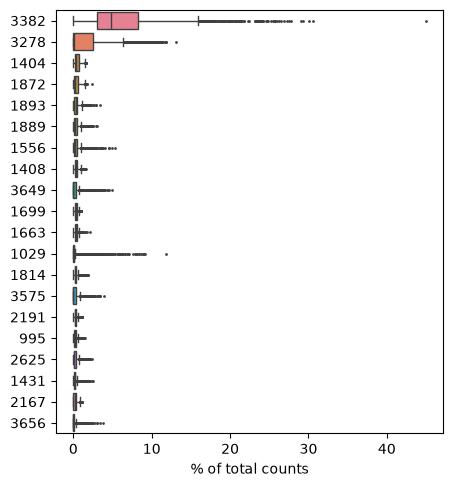

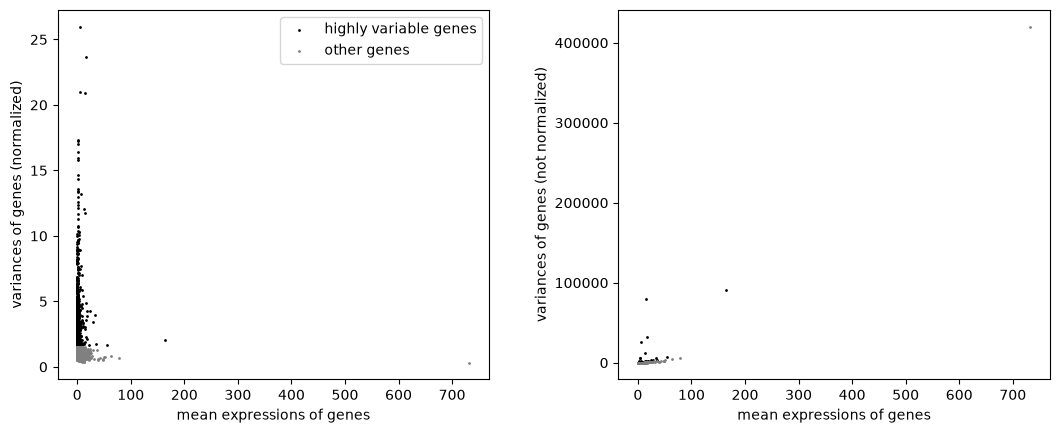

In [1]:
import scanpy as sc
from scanpy.io import read_h5ad

# load data
adata = read_h5ad("cortex.h5ad")
adata.var_names_make_unique()
adata.layers["counts"] = adata.X.copy()

# Show those genes that yield the highest fraction of counts in each single cell, across all cells.
sc.pl.highest_expr_genes(adata, n_top=20)

# basic filtering, asked to skip
#sc.pp.filter_cells(adata, min_genes=200) 
#sc.pp.filter_genes(adata, min_cells=3)

# filtering based on housekeeping genes, also skipped

# total count normalize to 10000 counts per cell, log scale
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# identify highly variable genes
sc.pp.highly_variable_genes(
    adata,
    flavor="seurat_v3",
    use="layers.counts",
)
sc.pl.highly_variable_genes(adata)

# scale to unit var, clip up to 10 std
sc.pp.scale(adata, max_value=10, out="layers.scaled")

# save
adata.write_h5ad("cortex_preprocessed.h5ad")

# (4)
Implement a VAE and train it on this cortex dataset. You can refer to any online material to implement the VAE. Extract the latent variable for each cell. Use the umap.UMAP() function in the package umap-learn to reduce the latent variable to 2D and make a scatter plot for all cells. The color of each dot (cell) should represent its ground truth cell type (can be found in the dataset). 

In [7]:
bad = ~torch.isfinite(X)

print("X shape:", tuple(X.shape))
print("NaN entries:", torch.isnan(X).sum().item())
print("Infinite entries:", torch.isinf(X).sum().item())
print("Cells with any invalid value:", bad.any(dim=1).sum().item())
print("Genes with any invalid value:", bad.any(dim=0).sum().item())

X shape: (3005, 19972)
NaN entries: 0
Infinite entries: 0
Cells with any invalid value: 0
Genes with any invalid value: 0


In [3]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from scanpy.io import read_h5ad

class VAE(nn.Module):
    def __init__(self, input_dim, latent_dim=4, hidden_dim=256):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2 * latent_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

        last_layer = self.encoder[-1]
        with torch.no_grad():
            last_layer.weight[latent_dim:].zero_()
            last_layer.bias[latent_dim:].zero_()

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=-1)
        return mu, logvar

    def forward(self, x):
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + std * eps
        x_hat = self.decoder(z)
        return x_hat, mu, logvar

adata = read_h5ad("cortex_preprocessed.h5ad")
X = torch.as_tensor(adata.layers["scaled"], dtype=torch.float32)

if not torch.isfinite(X).all():
    raise ValueError("The scaled expression matrix contains NaN or infinity.")

print(f"Training on {X.shape[0]:,} cells × {X.shape[1]:,} genes")

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loader = DataLoader(X, batch_size=128, shuffle=True)

model = VAE(input_dim=X.shape[1], latent_dim=4).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

model.train()

for epoch in range(30):
    recon_sum = 0.0
    kl_sum = 0.0
    max_logvar = float("-inf")

    for batch_idx, x in enumerate(loader):
        x = x.to(device)
        optimizer.zero_grad()

        x_hat, mu, logvar = model(x)

        # Sum over genes to obtain one reconstruction loss per cell.
        recon = 0.5 * (x_hat - x).square().sum(dim=1)

        # Sum over latent dimensions to obtain one KL loss per cell.
        kl = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1)

        loss = (recon + kl).mean()

        if not torch.isfinite(loss):
            raise FloatingPointError(
                f"Non-finite loss at epoch {epoch + 1}, batch {batch_idx + 1}"
            )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=5.0, error_if_nonfinite=True
        )
        optimizer.step()

        recon_sum += recon.detach().sum().item()
        kl_sum += kl.detach().sum().item()
        max_logvar = max(max_logvar, logvar.detach().max().item())

    mean_recon = recon_sum / len(X)
    mean_kl = kl_sum / len(X)

    print(
        f"Epoch {epoch + 1:2d} | "
        f"recon {mean_recon:.2f} | "
        f"KL {mean_kl:.2f} | "
        f"total {mean_recon + mean_kl:.2f} | "
        f"max logvar {max_logvar:.2f}"
    )

    torch.save(
    {
        "model_state_dict": model.state_dict(),
        "model_config": {
            "input_dim": X.shape[1],
            "hidden_dim": 256,
            "latent_dim": 4,
        },
        "gene_names": adata.var_names.tolist(),
    },
    "cortex_vae.pt",
)

Training on 3,005 cells × 19,972 genes
Epoch  1 | recon 8135.85 | KL 0.16 | total 8136.01 | max logvar 0.00
Epoch  2 | recon 7897.53 | KL 0.59 | total 7898.12 | max logvar -0.10
Epoch  3 | recon 7688.70 | KL 1.95 | total 7690.65 | max logvar -0.22
Epoch  4 | recon 7369.44 | KL 6.49 | total 7375.93 | max logvar -0.34
Epoch  5 | recon 7272.08 | KL 8.59 | total 7280.67 | max logvar -0.44
Epoch  6 | recon 7237.99 | KL 9.94 | total 7247.93 | max logvar -0.54
Epoch  7 | recon 7176.06 | KL 11.41 | total 7187.46 | max logvar -0.61
Epoch  8 | recon 7100.46 | KL 12.69 | total 7113.14 | max logvar -0.76
Epoch  9 | recon 7054.67 | KL 13.46 | total 7068.14 | max logvar -0.98
Epoch 10 | recon 7023.65 | KL 14.02 | total 7037.67 | max logvar -1.03
Epoch 11 | recon 6993.92 | KL 14.61 | total 7008.54 | max logvar -1.27
Epoch 12 | recon 6962.31 | KL 15.19 | total 6977.50 | max logvar -1.27
Epoch 13 | recon 6937.76 | KL 15.61 | total 6953.37 | max logvar -1.20
Epoch 14 | recon 6918.20 | KL 15.94 | total 6

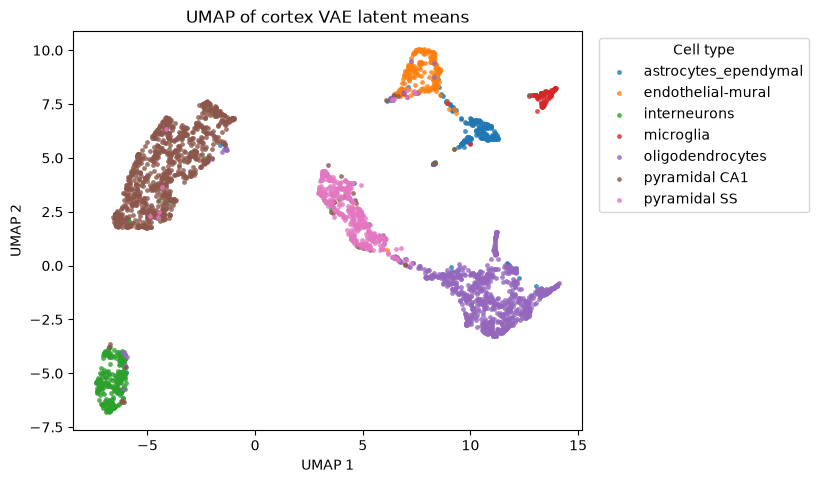

In [1]:
import torch
from torch import nn
from scanpy.io import read_h5ad

class VAE(nn.Module):
    def __init__(self, input_dim, latent_dim=4, hidden_dim=256):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2 * latent_dim),
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

        last_layer = self.encoder[-1]
        with torch.no_grad():
            last_layer.weight[latent_dim:].zero_()
            last_layer.bias[latent_dim:].zero_()

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=-1)
        return mu, logvar

    def forward(self, x):
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + std * eps
        x_hat = self.decoder(z)
        return x_hat, mu, logvar

# Load the saved model.
checkpoint = torch.load("cortex_vae.pt", map_location="cpu", weights_only=True)
model = VAE(**checkpoint["model_config"])
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Read the preprocessed data used for training.
adata = read_h5ad("cortex_preprocessed.h5ad")


from torch.utils.data import DataLoader

X = torch.as_tensor(adata.layers["scaled"], dtype=torch.float32)
loader = DataLoader(X, batch_size=128, shuffle=False)

latent_batches = []
with torch.no_grad():
    for x in loader:
        mu, _ = model.encode(x)
        latent_batches.append(mu)

latent = torch.cat(latent_batches, dim=0).numpy()
adata.obsm["X_vae"] = latent

import umap

latent = adata.obsm["X_vae"]
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
    n_jobs=1,
    compatibility_layout=True,
)

embedding = reducer.fit_transform(adata.obsm["X_vae"])
adata.obsm["X_umap_vae"] = embedding

import matplotlib.pyplot as plt

embedding = adata.obsm["X_umap_vae"]
labels = adata.obs["label"].astype("string").fillna("Unannotated")

fig, ax = plt.subplots(figsize=(8, 6))

for cell_type in sorted(labels.unique()):
    mask = labels.eq(cell_type).to_numpy(dtype=bool)
    ax.scatter(
        embedding[mask, 0],  # UMAP 1 for cells of this type
        embedding[mask, 1],  # UMAP 2 for the same cells
        label=cell_type,
        s=12,
        alpha=0.8,
        linewidths=0,
    )

ax.set(xlabel="UMAP 1", ylabel="UMAP 2", title="UMAP of cortex VAE latent means")
ax.set_aspect("equal")
ax.legend(title="Cell type", loc="upper left", bbox_to_anchor=(1.02, 1))

fig.tight_layout()
fig.savefig("cortex_vae_umap.png", dpi=300, bbox_inches="tight")
plt.show()

# (5)

Use Negative Binomial distribution to reconstruct the gene expression in the decoder of your VAE. Use data likelihood as your reconstruction loss. To do this, you need to use raw count data as your input (don’t use the logged values)

In [2]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import NegativeBinomial
from torch.utils.data import DataLoader
from scipy.sparse import issparse
from scanpy.io import read_h5ad


class NBVAE(nn.Module):
    def __init__(self, input_dim, latent_dim=4, hidden_dim=256):
        super().__init__()

        # The first half predicts latent means; the second predicts log variances.
        encoder_output = nn.Linear(hidden_dim, 2 * latent_dim)

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            encoder_output,
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )

        # One learnable inverse-dispersion parameter per gene, shared across cells.
        self.raw_theta = nn.Parameter(torch.zeros(input_dim))

        # Start every latent coordinate at variance 1.
        with torch.no_grad():
            encoder_output.weight[latent_dim:].zero_()
            encoder_output.bias[latent_dim:].zero_()

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=-1)
        return mu, logvar

    def decode(self, z):
        # Shape: (batch_size, n_genes). Each cell gets its own gene means.
        mean_counts = F.softplus(self.decoder(z)) + 1e-6

        # Shape: (n_genes,). These values broadcast across the batch.
        theta = F.softplus(self.raw_theta) + 1e-6

        return NegativeBinomial(
            total_count=theta,
            logits=mean_counts.log() - theta.log(),
        )

    def forward(self, x):
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)

        count_dist = self.decode(z)
        return count_dist, mu, logvar


# 1. Load raw counts for every cell and gene.
adata = read_h5ad("cortex_preprocessed.h5ad")

counts = adata.layers["counts"]

# Linear layers need floating-point inputs. The count values remain integers.
X = torch.as_tensor(counts, dtype=torch.float32)


# 2. Initialize a fresh model.
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_config = {
    "input_dim": X.shape[1],
    "latent_dim": 4,
    "hidden_dim": 256,
}

model = NBVAE(**model_config).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
loader = DataLoader(X, batch_size=128, shuffle=True)


# 3. Train.
model.train()

for epoch in range(30):
    recon_sum = 0.0
    kl_sum = 0.0
    max_logvar = float("-inf")

    for batch_idx, x in enumerate(loader):
        x = x.to(device)
        optimizer.zero_grad()

        count_dist, mu, logvar = model(x)

        # log_prob(x) has one entry per cell and gene, including observed zeros.
        # Sum over genes to get one negative log likelihood per cell.
        recon = -count_dist.log_prob(x).sum(dim=1)

        # Gaussian latent KL, summed over the four latent dimensions.
        kl = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1)

        loss = (recon + kl).mean()

        if not torch.isfinite(loss):
            raise FloatingPointError(
                f"Non-finite loss at epoch {epoch + 1}, batch {batch_idx + 1}"
            )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=5.0, error_if_nonfinite=True
        )
        optimizer.step()

        recon_sum += recon.detach().sum().item()
        kl_sum += kl.detach().sum().item()
        max_logvar = max(max_logvar, logvar.detach().max().item())

    mean_recon = recon_sum / len(X)
    mean_kl = kl_sum / len(X)

    print(
        f"Epoch {epoch + 1:2d} | "
        f"NB NLL {mean_recon:.2f} | "
        f"KL {mean_kl:.2f} | "
        f"total {mean_recon + mean_kl:.2f} | "
        f"max logvar {max_logvar:.2f}"
    )

    # Save the latest epoch separately from your original cortex_vae.pt.
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "model_config": model_config,
            "gene_names": adata.var_names.tolist(),
            "input_layer": "counts",
            "epoch": epoch + 1,
        },
        "cortex_nb_vae.pt",
    )

Epoch  1 | NB NLL 20681.79 | KL 7.18 | total 20688.97 | max logvar 0.00
Epoch  2 | NB NLL 18394.80 | KL 18.54 | total 18413.34 | max logvar -0.16
Epoch  3 | NB NLL 16558.86 | KL 22.87 | total 16581.73 | max logvar -0.19
Epoch  4 | NB NLL 15331.76 | KL 26.80 | total 15358.56 | max logvar -0.24
Epoch  5 | NB NLL 14463.62 | KL 31.59 | total 14495.21 | max logvar -0.34
Epoch  6 | NB NLL 13880.24 | KL 36.67 | total 13916.91 | max logvar -0.54
Epoch  7 | NB NLL 13499.73 | KL 41.66 | total 13541.39 | max logvar -0.82
Epoch  8 | NB NLL 13186.88 | KL 44.53 | total 13231.41 | max logvar -1.02
Epoch  9 | NB NLL 12891.21 | KL 46.93 | total 12938.14 | max logvar -1.14
Epoch 10 | NB NLL 12655.13 | KL 50.22 | total 12705.35 | max logvar -1.26
Epoch 11 | NB NLL 12495.08 | KL 52.51 | total 12547.59 | max logvar -1.41
Epoch 12 | NB NLL 12388.15 | KL 53.40 | total 12441.55 | max logvar -1.44
Epoch 13 | NB NLL 12321.95 | KL 53.79 | total 12375.74 | max logvar -1.55
Epoch 14 | NB NLL 12273.79 | KL 53.49 | 